## floodscope demo: mapping a real flood from public Sentinel-1 SAR

Optical satellites can't see through cloud cover -- which is exactly the condition
during and after most floods (heavy rain, storm systems). Synthetic Aperture Radar
(SAR) sensors like Sentinel-1 image straight through clouds, so this notebook maps a
real, documented flood using nothing but public Sentinel-1 GRD scenes, read directly
over HTTPS with no download step and no credentials.

**Event**: the July 2023 Cheongju / Miho River flood, South Korea -- a temporary
embankment near the Miho River breached on 2023-07-15 after days of heavy rain,
flooding the Gungpyeong 2 underpass in Osong.

**Approach**: compare a pre-flood and a post-flood Sentinel-1 scene from the *same
relative orbit* (so both share the same viewing geometry), and flag pixels that
darkened sharply between the two -- calm open water is a near-specular reflector, so
new inundation shows up as a sharp drop in radar backscatter.

1. Find a same-relative-orbit pre/post scene pair around the flood date
2. GCP-geocode both scenes over the AOI (raw Sentinel-1 GRD has no built-in affine
   transform -- only ground control points)
3. Convert to a dB backscatter proxy and despeckle
4. Detect newly-flooded pixels via a darkening threshold + connected-component filter
5. Estimate the flooded area and export the result as a Cloud-Optimized GeoTIFF

### Scope

This is a simple, illustrative pipeline, not a validated operational flood product:
- No radiometric calibration (needs a per-pixel gain LUT from the product's
  calibration annotation) -- fine for same-geometry relative change detection, not for
  absolute backscatter values.
- Only detects the classic *dark open-water* signature; flooded vegetation or urban
  areas can instead brighten via double-bounce scattering, which this simple threshold
  does not capture.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from floodscope import (
    despeckle,
    detect_flood,
    filter_same_orbit,
    find_nearest_item,
    read_geocoded_band,
    search_items,
    to_db,
)

AOI_BBOX = (127.35, 36.55, 127.60, 36.80)  # Miho River / Cheongju, South Korea
PRE_DATE = "2023-06-24"
POST_DATE = "2023-07-18"

### 1. Find a same-relative-orbit scene pair

Sentinel-1's viewing geometry depends on its relative orbit (it repeats every 12
days), so comparing two acquisitions from *different* orbits mixes real change with
geometry-driven brightness differences. `filter_same_orbit` keeps only candidates that
share the reference scene's `sat:relative_orbit` and `sat:orbit_state`.

In [2]:
pre_candidates = search_items(bbox=AOI_BBOX, datetime="2023-06-15T00:00:00Z/2023-07-01T23:59:59Z")
pre_item = find_nearest_item(pre_candidates, PRE_DATE)
print(f"pre:  {pre_item.id}  ({pre_item.properties['datetime'][:10]}, orbit {pre_item.properties['sat:relative_orbit']})")

post_candidates = search_items(bbox=AOI_BBOX, datetime="2023-07-10T00:00:00Z/2023-07-25T23:59:59Z")
post_candidates = filter_same_orbit(post_candidates, pre_item)
post_item = find_nearest_item(post_candidates, POST_DATE)
print(f"post: {post_item.id}  ({post_item.properties['datetime'][:10]}, orbit {post_item.properties['sat:relative_orbit']})")

pre:  S1A_IW_GRDH_1SDV_20230624T092358_20230624T092423_049126_05E83E  (2023-06-24, orbit 54)


post: S1A_IW_GRDH_1SDV_20230718T092400_20230718T092425_049476_05F302  (2023-07-18, orbit 54)


### 2. GCP-geocode both scenes

Raw Sentinel-1 GRD "measurement" GeoTIFFs carry no affine transform, only ~200 Ground
Control Points. `read_geocoded_band` warps through those GCPs (via `rasterio`'s
`WarpedVRT`) into a real CRS, windowed directly to our AOI -- reading only the bytes
needed for that window, not the full ~1 GB scene.

In [3]:
pre_dn, transform, crs = read_geocoded_band(pre_item.assets["vv"].href, AOI_BBOX)
post_dn, _, _ = read_geocoded_band(post_item.assets["vv"].href, AOI_BBOX)
print(f"window shape: {pre_dn.shape}, crs: {crs}")

window shape: (2435, 2435), crs: EPSG:4326


### 3. Convert to dB and despeckle, then look at the raw before/after

Even before any change detection, the river channel is visible as a dark line running
through both scenes.

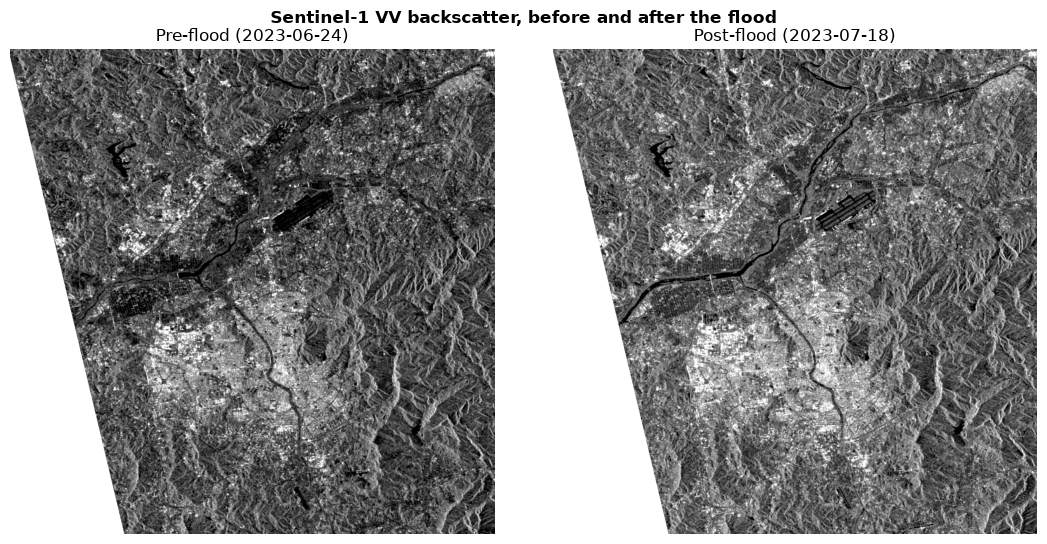

In [4]:
pre_db = despeckle(to_db(pre_dn))
post_db = despeckle(to_db(post_dn))

vmin, vmax = np.nanpercentile(post_db, [1, 99])
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(pre_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title(f"Pre-flood ({pre_item.properties['datetime'][:10]})")
axes[0].axis("off")
axes[1].imshow(post_db, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title(f"Post-flood ({post_item.properties['datetime'][:10]})")
axes[1].axis("off")
fig.suptitle("Sentinel-1 VV backscatter, before and after the flood", fontweight="bold")
plt.tight_layout()
plt.show()

### 4. Detect the flood extent

`detect_flood` flags pixels that darkened by more than a threshold (default -3 dB),
then drops connected clusters smaller than `min_pixels` -- isolated single pixels are
far more often residual speckle noise than real flooding.

Estimated new-water area: 2.49 km^2


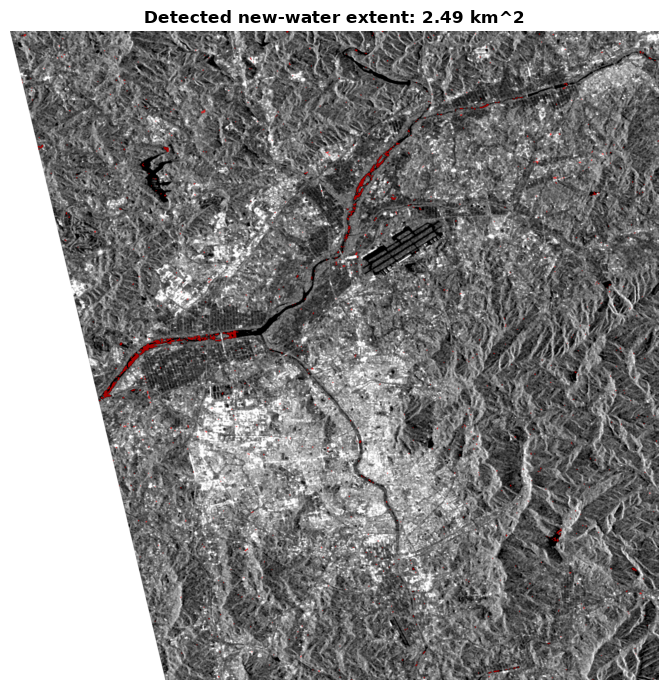

In [5]:
result = detect_flood(pre_db, post_db, transform, crs)
print(f"Estimated new-water area: {result.area_km2:.2f} km^2")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(post_db, cmap="gray", vmin=vmin, vmax=vmax)
overlay = np.zeros((*result.mask.shape, 4))
overlay[result.mask] = [1, 0, 0, 0.65]
ax.imshow(overlay)
ax.set_title(f"Detected new-water extent: {result.area_km2:.2f} km^2", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

Notice the detected extent concentrates heavily right where the tributary joins the
main river channel -- exactly the kind of confluence backwater location where
overbank flooding and embankment breaches are most likely.

### 5. Export the result

Two bands: the boolean flood mask, and the underlying dB difference (useful for
re-thresholding without redoing the geocoding/despeckling).

In [6]:
from floodscope import export_cog

export_cog(result, "flood_cheongju_2023.tif")
print("Wrote flood_cheongju_2023.tif")

Wrote flood_cheongju_2023.tif


## Summary

- Sentinel-1 SAR imaged straight through the storm system that caused this flood --
  something no optical sensor could have done for these dates.
- A same-relative-orbit pre/post pair is what makes a simple darkening threshold
  meaningful without full radiometric calibration: the viewing geometry cancels out,
  so the *change* between the two dates is attributable to the ground, not the sensor.
- The detected extent lines up with the real river network and, especially, the
  tributary confluence -- consistent with the flood's actual cause (an embankment
  breach near the Miho River).
- This is a simple, illustrative pipeline (uncalibrated backscatter, dark-open-water
  detection only) -- a research-grade flood product would add radiometric calibration,
  a more advanced despeckling filter, and a double-bounce-aware classifier for flooded
  vegetation/urban areas.